# Статистический анализ продаж «Соседушки»

## 1. Задача и план
«Соседушка» — учебная сеть продуктовых магазинов. В проекте рассматриваются продажи за 2024–2025 годы. Задача — понять, какие сравнения магазинов полезны для управления сетью: как меняются продажи, насколько различаются форматы и есть ли связь между картой лояльности и размером покупки.

Результаты предназначены для руководителя розницы и менеджера программы лояльности. Они помогут выбрать показатели для сравнения магазинов и направления дальнейших экспериментов. Данных о затратах, посещаемости и прибыли нет, поэтому проект не оценивает рентабельность и конверсию.

Источник — учебный файл `sosedushka.xlsx` из модуля Power BI Simulative: https://disk.yandex.ru/i/rD5Ei1bAI60oSA. Используются листы `fact_sales` и `dim_stores`. Лист `fact_sales_dirty` — отдельный материал для упражнений по очистке, смешивать его с основной таблицей нельзя. Данные учебные: выводы относятся к этому набору, а не к реальной торговой сети.

### План шести проверок
1. Отличаются ли распределения среднего чека магазина между форматами?
2. Есть ли систематическое изменение годовой выручки магазинов между 2024 и 2025 годами?
3. Есть ли систематическая разница среднего чека с картой и без карты внутри магазинов?
4. Отличаются ли распределения доли чеков с картой между форматами?
5. Связана ли площадь магазина с его выручкой?
6. Есть ли систематическая разница среднего чека выходных и будних дней внутри магазинов?

Основной период — полный 2025 год; 2024 год нужен для сопоставления. Все альтернативы двусторонние по смыслу: заранее не предполагается, в какую сторону направлена разница или связь. Для общих тестов различия форматов большие значения статистики означают любое различие, поэтому используется верхний хвост распределения статистики.

Уровень значимости — 0,05. Шесть проверок образуют одну семью; окончательные решения принимаются после поправки Холма. Анализ исследовательский, план не является предварительной регистрацией: часть данных уже изучалась в Power BI.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
import scipy
from scipy import stats
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

ROOT = Path.cwd()
assert (ROOT / 'data/sosedushka.xlsx').exists(), 'Запустите ноутбук из папки проекта'
for folder in ['results', 'figures']:
    (ROOT / folder).mkdir(exist_ok=True)
pd.set_option('display.max_columns', 15)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')
plt.rcParams.update({'font.family': 'DejaVu Sans', 'figure.dpi': 120,
                     'axes.spines.top': False, 'axes.spines.right': False})
SEED = 20260921
ALPHA = 0.05
versions = {'python': sys.version.split()[0], 'pandas': pd.__version__,
            'numpy': np.__version__, 'scipy': scipy.__version__,
            'matplotlib': matplotlib.__version__}
print(versions)

{'python': '3.12.14', 'pandas': '3.0.1', 'numpy': '2.3.5', 'scipy': '1.18.1', 'matplotlib': '3.11.2'}


## 2. Подготовка данных
Одна строка исходной таблицы — позиция чека, а не отдельная покупка. Сначала проверяются ключи, пропуски, даты и сумма после скидки. Затем позиции складываются в чеки. Иначе чек из пяти товаров будет ошибочно учтён как пять покупок.

Отсутствующий `id_клиента` означает чек без известной карты. Это не основание удалять покупку. Способ оплаты не определяет наличие карты лояльности. Выбросы не удаляются только из-за большого размера: сначала проверяется корректность суммы.

In [2]:
file = ROOT / 'data/sosedushka.xlsx'
sales = pd.read_excel(file, sheet_name='fact_sales')
stores = pd.read_excel(file, sheet_name='dim_stores')
sales['дата_время'] = pd.to_datetime(sales['дата_время'], errors='raise')
required = ['id_чека', 'дата_время', 'id_магазина', 'id_товара',
            'количество', 'цена_за_единицу', 'скидка_процент', 'сумма_строки']
assert sales[required].notna().all().all()
assert stores['id_магазина'].notna().all() and stores['id_магазина'].is_unique
assert sales['id_магазина'].isin(stores['id_магазина']).all()
assert (sales['количество'] > 0).all()
assert (sales['цена_за_единицу'] >= 0).all()
assert sales['скидка_процент'].between(0, 100).all()
expected = sales['количество'] * sales['цена_за_единицу'] * (1 - sales['скидка_процент'] / 100)
rounding_error = (expected - sales['сумма_строки']).abs().max()
assert rounding_error <= 0.005001
consistency = sales.groupby('id_чека')[['дата_время', 'id_магазина', 'id_клиента']].nunique(dropna=False)
assert consistency.eq(1).all().all()
assert sales.duplicated().sum() == 0

receipts = sales.groupby('id_чека', as_index=False).agg(
    date=('дата_время', 'first'), store=('id_магазина', 'first'),
    customer=('id_клиента', 'first'), amount=('сумма_строки', 'sum'),
    units=('количество', 'sum'))
receipts = receipts.merge(stores.rename(columns={
    'id_магазина': 'store', 'наименование_магазина': 'name',
    'формат_магазина': 'format', 'регион': 'region', 'площадь_кв_м': 'area'}),
    on='store', how='left', validate='many_to_one')
receipts['year'] = receipts['date'].dt.year
receipts['card'] = receipts['customer'].notna()
receipts['weekend'] = receipts['date'].dt.dayofweek >= 5
assert set(receipts['year']) == {2024, 2025}
assert np.isclose(receipts['amount'].sum(), sales['сумма_строки'].sum())
r25 = receipts.loc[receipts['year'] == 2025].copy()
quality = {'positions': len(sales), 'receipts': len(receipts),
           'stores': receipts['store'].nunique(), 'duplicate_rows': int(sales.duplicated().sum()),
           'missing_customer_positions': int(sales['id_клиента'].isna().sum()),
           'max_rounding_error': float(rounding_error),
           'first_date': str(receipts['date'].min()), 'last_date': str(receipts['date'].max())}
display(pd.Series(quality, name='Проверка данных').to_frame())
display(sales[required + ['id_клиента']].isna().sum().rename('Пропуски').to_frame())
(ROOT / 'results/data_quality.json').write_text(json.dumps(quality, ensure_ascii=False, indent=2), encoding='utf-8')

,Проверка данных
positions,81238
receipts,22790
stores,20
duplicate_rows,0
missing_customer_positions,36494
max_rounding_error,0.005
first_date,2024-01-01 09:42:00
last_date,2025-12-31 22:40:00


,Пропуски
id_чека,0
дата_время,0
id_магазина,0
id_товара,0
количество,0
цена_за_единицу,0
скидка_процент,0
сумма_строки,0
id_клиента,36494


246

## 3. Единица анализа и ограничения
Для описания покупок используются чеки. Для всех шести проверок единицей анализа выбран **магазин**: всего 20 наблюдений. Чеки одного магазина зависят от его формата, ассортимента и местоположения; одни и те же покупатели возвращаются. Поэтому десятки тысяч товарных строк нельзя считать независимыми наблюдениями для проверки различий магазинов.

Парные сравнения сохраняют один и тот же магазин по обе стороны сравнения. Все магазины получают одинаковый вес. Например, средняя разность по магазинам не равна разности двух средних чеков всей сети, взвешенных числом покупок.

Даже магазины не обязательно полностью независимы: у них общие акции и экономические условия. Мы условно рассматриваем их как независимые единицы. Все p-value ниже иллюстрируют статистический подход при этом допущении. Поскольку это все 20 магазинов учебной сети, наблюдаемые различия для данной сети уже известны; перенос результатов на другие сети или будущие годы требует дополнительных данных. Никакой тест здесь не устанавливает причинность.

In [3]:
annual = receipts.groupby('year').agg(revenue=('amount', 'sum'),
    checks=('amount', 'size'), mean_check=('amount', 'mean'), median_check=('amount', 'median'))
display(annual)
description = r25['amount'].describe(percentiles=[.05, .25, .5, .75, .95]).to_frame('Чек, руб.')
description.loc['IQR'] = r25['amount'].quantile(.75) - r25['amount'].quantile(.25)
description.loc['skewness'] = r25['amount'].skew()
display(description)

store25 = r25.groupby('store').agg(name=('name', 'first'), format=('format', 'first'),
    region=('region', 'first'), area=('area', 'first'), revenue=('amount', 'sum'),
    checks=('amount', 'size'), avg_check=('amount', 'mean'), median_check=('amount', 'median'),
    card_share=('card', 'mean'))
year_revenue = receipts.pivot_table(index='store', columns='year', values='amount', aggfunc='sum')
card_means = r25.pivot_table(index='store', columns='card', values='amount', aggfunc='mean')
week_means = r25.pivot_table(index='store', columns='weekend', values='amount', aggfunc='mean')
assert year_revenue.notna().all().all() and card_means.notna().all().all() and week_means.notna().all().all()
store25['growth_pct'] = (year_revenue[2025] / year_revenue[2024] - 1) * 100
store25['revenue_diff'] = year_revenue[2025] - year_revenue[2024]
store25['card_diff'] = card_means[True] - card_means[False]
store25['weekend_diff'] = week_means[True] - week_means[False]
format_summary = store25.groupby('format').agg(stores=('name', 'size'),
    median_store_check=('avg_check', 'median'), median_card_share=('card_share', 'median'),
    median_growth_pct=('growth_pct', 'median'))
display(format_summary)
display(r25.groupby('card').agg(checks=('amount', 'size'), avg_check=('amount', 'mean')))
annual.to_csv(ROOT / 'results/annual.csv', encoding='utf-8-sig')
store25.to_csv(ROOT / 'results/stores_2025.csv', encoding='utf-8-sig')
description.to_csv(ROOT / 'results/receipt_description.csv', encoding='utf-8-sig')

,revenue,checks,mean_check,median_check
year,,,,
2024,"10,432,017.930",11019,946.730,723.800
2025,"11,457,582.400",11771,973.374,739.960


,"Чек, руб."
count,"11,771.000"
mean,973.374
std,841.520
min,33.480
5%,87.875
25%,343.630
50%,739.960
75%,"1,364.445"
95%,"2,691.575"
max,"6,947.380"


,stores,median_store_check,median_card_share,median_growth_pct
format,,,,
гипермаркет,4,"1,688.156",0.553,10.463
супермаркет,9,981.406,0.550,10.742
у дома,7,483.373,0.540,10.702


,checks,avg_check
card,,
False,5261,982.216
True,6510,966.228


Среднее нужно для расчёта выручки на покупку. Медиана показывает размер типичной покупки и менее чувствительна к редким большим чекам. Стандартное отклонение описывает разброс вокруг среднего, а межквартильный размах (IQR) — ширину центральной половины наблюдений. Квантили 5% и 95% показывают диапазон большей части чеков без удаления хвостов. Различие среднего и медианы рассматривается вместе с гистограммой.

В 2025 году средний чек — 973,37 руб., медиана — 739,96 руб., стандартное отклонение — 841,52 руб. Центральные 50% чеков лежат между 343,63 и 1 364,45 руб. Среднее выше медианы, коэффициент асимметрии равен 1,52: распределение имеет длинный правый хвост. Поэтому один общий средний чек плохо описывает весь диапазон покупок. Большие чеки не удаляются: они прошли проверку сумм и могут быть обычными крупными закупками. Дополнительно общий разброс отражает смешение разных форматов магазинов.

Форматы нельзя сравнивать только по выручке: гипермаркеты отличаются площадью, ассортиментом и характером покупок. Даже высокий средний чек сам по себе не означает лучшую эффективность.

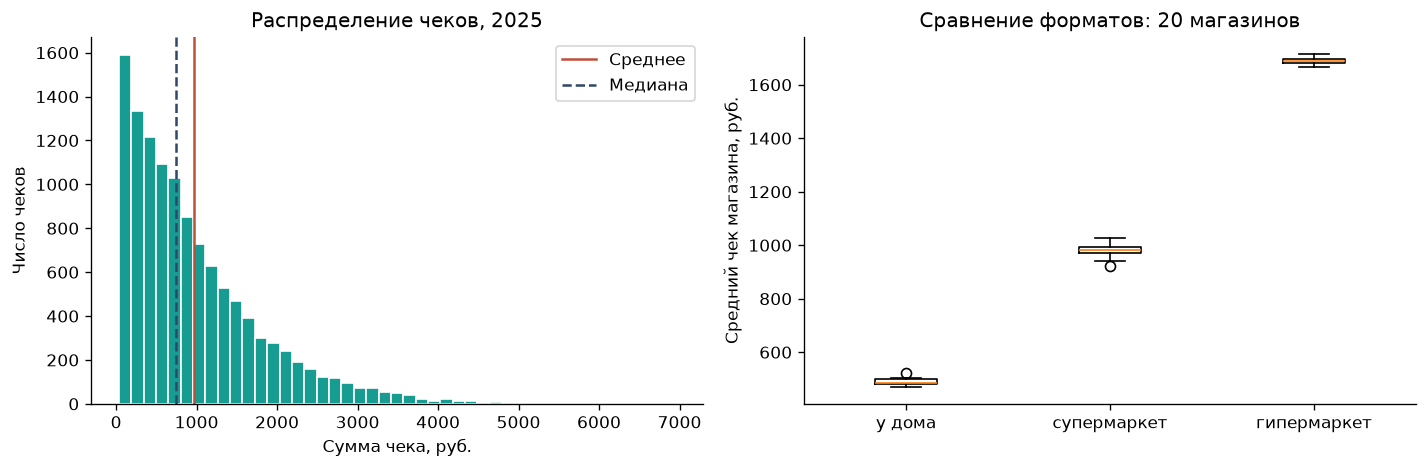

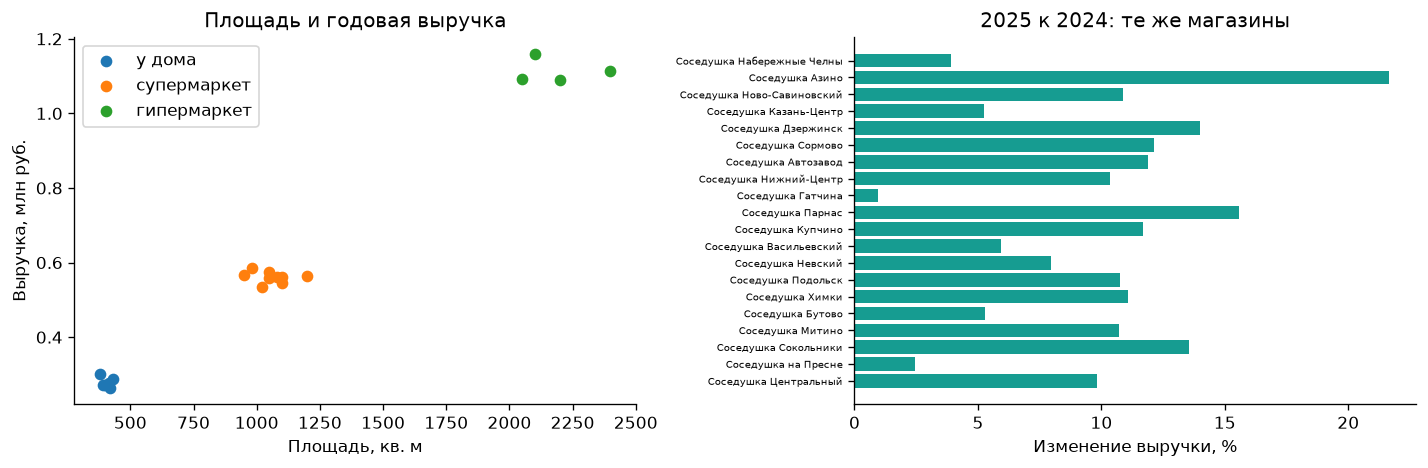

In [4]:
order = ['у дома', 'супермаркет', 'гипермаркет']
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(r25['amount'], bins=45, color='#169c91', edgecolor='white')
axes[0].axvline(r25['amount'].mean(), color='#be503a', label='Среднее')
axes[0].axvline(r25['amount'].median(), color='#30466b', linestyle='--', label='Медиана')
axes[0].set(xlabel='Сумма чека, руб.', ylabel='Число чеков', title='Распределение чеков, 2025')
axes[0].legend()
axes[1].boxplot([store25.loc[store25['format']==f, 'avg_check'] for f in order], tick_labels=order)
axes[1].set(ylabel='Средний чек магазина, руб.', title='Сравнение форматов: 20 магазинов')
fig.tight_layout()
fig.savefig(ROOT / 'figures/01_checks.png')
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for fmt in order:
    part = store25.loc[store25['format'] == fmt]
    axes[0].scatter(part['area'], part['revenue']/1e6, label=fmt)
axes[0].set(xlabel='Площадь, кв. м', ylabel='Выручка, млн руб.', title='Площадь и годовая выручка')
axes[0].legend()
axes[1].barh(store25['name'], store25['growth_pct'], color='#169c91')
axes[1].set(xlabel='Изменение выручки, %', title='2025 к 2024: те же магазины')
axes[1].tick_params(axis='y', labelsize=6)
fig.tight_layout()
fig.savefig(ROOT / 'figures/02_stores.png')
plt.show()

## 4. Методы проверки
**Сравнение форматов (H1, H4).** Используется статистика Краскела—Уоллиса на магазинных показателях. Она проверяет равенство распределений; без дополнительных предположений о форме распределений это не тест только медиан. В одном формате всего четыре магазина, поэтому p-value оценивается перестановкой меток форматов (9 999 перестановок), а не только асимптотической формулой. Допущение — обменяемость независимых магазинных наблюдений при H0. Значимый общий результат не доказывает различие каждой пары форматов.

**Парные сравнения (H2, H3, H6).** Используется точный критерий знаков: считаем положительные и отрицательные разности по магазинам. При H0 вероятность положительного знака среди ненулевых разностей равна 0,5. Для непрерывных разностей это проверка нулевой медианы. Точные нули исключаются и отдельно считаются. В отличие от критерия Уилкоксона, здесь не требуется симметрия распределения разностей, но теряется информация о величине изменений. Поэтому отдельно показываются размеры эффектов.

**Связь (H5).** Корреляция Спирмена описывает монотонную связь рангов площади и выручки. p-value получаем перестановкой выручки между магазинами (9 999 перестановок). H0 для перестановок — независимость площади и выручки при обменяемости магазинов. Нулевая корреляция и полная независимость не тождественны; статистика чувствительна прежде всего к монотонной связи.

Для средних парных разностей дополнительно строится процентильный bootstrap-интервал: 10 000 повторных выборок **магазинов**, а не товарных строк. Это приблизительные индивидуальные 95%-интервалы при независимости магазинов, без поправки на множественность. Они оценивают среднюю разность, тогда как критерий знаков проверяет баланс знаков; окончательные решения по гипотезам принимаются по p-value с поправкой Холма, не по этим интервалам.

In [5]:
tests = []
effects = []

def compare_formats(column, hypothesis):
    groups = [store25.loc[store25['format'] == f, column].to_numpy() for f in order]
    def statistic(*samples, axis):
        return stats.kruskal(*samples, axis=axis).statistic
    result = stats.permutation_test(groups, statistic, permutation_type='independent',
        vectorized=True, n_resamples=9999, batch=256, alternative='greater', rng=np.random.default_rng(SEED))
    tests.append({'hypothesis': hypothesis, 'method': 'Kruskal + permutation',
                  'statistic': result.statistic, 'p_raw': result.pvalue, 'n': len(store25)})
    print(hypothesis, 'H =', round(result.statistic, 4), 'p =', result.pvalue)

def paired_sign(column, hypothesis):
    differences = store25[column].to_numpy()
    nonzero = differences[differences != 0]
    positive = int((nonzero > 0).sum())
    result = stats.binomtest(positive, len(nonzero), .5, alternative='two-sided')
    tests.append({'hypothesis': hypothesis, 'method': 'Exact sign test',
                  'statistic': positive, 'p_raw': result.pvalue, 'n': len(nonzero)})
    rng = np.random.default_rng(SEED)
    bootstrap_means = rng.choice(differences, size=(10000, len(differences)), replace=True).mean(axis=1)
    low, high = np.quantile(bootstrap_means, [.025, .975])
    effects.append({'hypothesis': hypothesis, 'positive': positive,
        'negative': int((nonzero < 0).sum()), 'zero': int((differences == 0).sum()),
        'mean_diff_rub': differences.mean(), 'median_diff_rub': np.median(differences),
        'mean_ci_low': low, 'mean_ci_high': high})
    display(pd.DataFrame([effects[-1]]))
    print('p =', result.pvalue)

### H1. Формат и средний чек
Разные форматы рассчитаны на разные покупательские сценарии. Проверка нужна, чтобы понять, насколько оправдано сравнивать средний чек только внутри формата.

- H0: распределения среднего чека магазина одинаковы в трёх форматах.
- H1: хотя бы одно распределение отличается.
- Типы данных: номинальный формат и количественный денежный показатель.
- Наблюдение: средний чек одного магазина за 2025 год; проверка не сравнивает независимость отдельных чеков.

In [6]:
compare_formats('avg_check', 'H1')

H1 H = 16.3429 p = 0.0001


### H2. Изменение годовой выручки
Рост общей суммы сети может быть обусловлен несколькими крупными точками. Проверка знаков изменений показывает, насколько широко рост распространён среди магазинов.

- H0: положительное и отрицательное изменение выручки магазина равновероятны.
- H1: вероятности отличаются.
- Типы данных: парные денежные показатели, затем бинарный знак разности.
- Разность: выручка 2025 минус выручка 2024 того же магазина.

Проверяется номинальная годовая выручка. Инфляция не учтена; 2024 — високосный год. Это не тест реального роста покупательной способности.

In [7]:
paired_sign('revenue_diff', 'H2')

,hypothesis,positive,negative,zero,mean_diff_rub,median_diff_rub,mean_ci_low,mean_ci_high
0,H2,20,0,0,"51,278.223","51,559.090","36,562.946","68,368.787"


p = 1.9073486328125e-06


### H3. Средний чек с картой и без карты
В Power BI общий средний чек с картой оказался немного ниже. Однако состав магазинов и число покупок в них могут влиять на общую разницу. Поэтому сравнение проводится внутри каждой точки.

- H0: разность среднего чека «с картой минус без карты» одинаково часто положительна и отрицательна по магазинам.
- H1: баланс знаков отличается от 50/50.
- Типы данных: бинарное наличие карты и количественная сумма чека, агрегированная по магазину.

Это сравнение покупок разных людей, а не эксперимент с выдачей карты. Скидки, покупательские привычки и состав корзины могут объяснять наблюдаемую связь.

In [8]:
paired_sign('card_diff', 'H3')

,hypothesis,positive,negative,zero,mean_diff_rub,median_diff_rub,mean_ci_low,mean_ci_high
0,H3,6,14,0,-14.696,-23.273,-32.193,3.227


p = 0.11531829833984375


### H4. Формат и доля чеков с картой
При планировании программы лояльности полезно проверить, различается ли использование карты по форматам.

- H0: распределения магазинной доли чеков с картой одинаковы в трёх форматах.
- H1: хотя бы одно распределение отличается.
- Типы данных: номинальный формат и доля, рассчитанная из бинарного признака карты.

Доля = число чеков с известным id клиента / все чеки магазина. Это доля покупок, а не доля людей: частый покупатель может дать несколько чеков. Обычный χ² по всем чекам дал бы необоснованно большой размер независимой выборки; здесь сохраняется магазинный уровень.

In [9]:
compare_formats('card_share', 'H4')

H4 H = 0.1858 p = 0.9216


### H5. Площадь и выручка
Крупные помещения потенциально позволяют разместить больше товаров и обслужить больше покупателей. Проверка показывает, связана ли площадь с выручкой в этой сети.

- H0 для перестановочного теста: площадь и выручка независимы.
- H1: присутствует связь, проявляющаяся в положительной или отрицательной корреляции рангов.
- Типы данных: два количественных показателя; расчёт проводится по их рангам.

Формат и расположение могут объяснять связь. Даже сильная корреляция не означает, что расширение конкретного магазина повысит его выручку.

In [10]:
x = stats.rankdata(store25['area'].to_numpy())
y = stats.rankdata(store25['revenue'].to_numpy())
x = (x - x.mean()) / np.linalg.norm(x - x.mean())
y = (y - y.mean()) / np.linalg.norm(y - y.mean())
def correlation(y_permuted, axis):
    return np.sum(y_permuted * x, axis=axis)
correlation_result = stats.permutation_test((y,), correlation, permutation_type='pairings',
    vectorized=True, alternative='two-sided', n_resamples=9999, batch=256,
    rng=np.random.default_rng(SEED))
rho = stats.spearmanr(store25['area'], store25['revenue']).statistic
assert np.isclose(rho, correlation_result.statistic)
tests.append({'hypothesis': 'H5', 'method': 'Spearman + permutation',
              'statistic': rho, 'p_raw': correlation_result.pvalue, 'n': len(store25)})
print('rho =', round(rho, 4), 'p =', correlation_result.pvalue)
# Эти коэффициенты описательные: отдельных дополнительных тестов не проводим.
display(pd.DataFrame([{'format': f, 'n': len(g),
    'rho_within_format': stats.spearmanr(g['area'], g['revenue']).statistic}
    for f, g in store25.groupby('format')]))

rho = 0.8292 p = 0.0002


,format,n,rho_within_format
0,гипермаркет,4,0.000
1,супермаркет,9,-0.286
2,у дома,7,-0.143


### H6. Выходные и будни
В выходные покупатели могут делать более крупные закупки. Проверка нужна, чтобы понять, есть ли устойчивое различие размера покупки внутри магазинов.

- H0: разность среднего чека «выходные минус будни» равновероятно положительна и отрицательна.
- H1: баланс знаков отличается от 50/50.
- Типы данных: календарная категория и парные средние денежные показатели.

Выходные — суббота и воскресенье, без отдельного учёта праздников. Средний чек взвешен покупками внутри группы дней. Сравниваются не суммы выручки за 2 и 5 дней: такое сравнение было бы несопоставимым. Результат ничего не говорит о почасовой загрузке касс.

In [11]:
paired_sign('weekend_diff', 'H6')

,hypothesis,positive,negative,zero,mean_diff_rub,median_diff_rub,mean_ci_low,mean_ci_high
0,H6,15,5,0,88.033,79.189,51.618,124.722


p = 0.04138946533203125


## 5. Общий результат с поправкой на шесть проверок
Поправка Холма уменьшает вероятность хотя бы одного ложного отклонения H0 в семействе проверок. Сначала p-value сортируются; минимальное умножается на 6, следующее на 5 и так далее. Затем обеспечивается неубывание скорректированных значений. Это не выбор только «удачных» результатов: в таблицу включены все шесть гипотез.

`H0 не отклонена` означает недостаток свидетельств при данном объёме данных. Это не доказательство равенства и не подтверждение отсутствия практически важного эффекта.

In [12]:
results = pd.DataFrame(tests).sort_values('hypothesis').reset_index(drop=True)
p = results['p_raw'].to_numpy()
indices = np.argsort(p)
adjusted = np.minimum(1, np.maximum.accumulate(p[indices] * np.arange(len(p), 0, -1)))
p_holm = np.empty(len(p))
p_holm[indices] = adjusted
results['p_holm'] = p_holm
results['decision'] = np.where(p_holm < ALPHA, 'H0 отклонена', 'H0 не отклонена')
display(results.style.format({'statistic':'{:.5f}', 'p_raw':'{:.6g}', 'p_holm':'{:.6g}'}))
effects_table = pd.DataFrame(effects)
display(effects_table)
results.to_csv(ROOT / 'results/hypotheses.csv', index=False, encoding='utf-8-sig')
effects_table.to_csv(ROOT / 'results/paired_effects.csv', index=False, encoding='utf-8-sig')
(ROOT / 'results/versions.json').write_text(json.dumps(versions, indent=2), encoding='utf-8')
assert len(results) == 6 and results['hypothesis'].is_unique
assert results[['p_raw', 'p_holm']].ge(0).all().all()
assert results[['p_raw', 'p_holm']].le(1).all().all()
assert (results['p_holm'] >= results['p_raw'] - 1e-12).all()

,hypothesis,method,statistic,p_raw,n,p_holm,decision
0,H1,Kruskal + permutation,16.34286,0.0001,20,0.0005,H0 отклонена
1,H2,Exact sign test,20.00000,1.90735e-06,20,1.14441e-05,H0 отклонена
2,H3,Exact sign test,6.00000,0.115318,20,0.230637,H0 не отклонена
3,H4,Kruskal + permutation,0.18583,0.9216,20,0.9216,H0 не отклонена
4,H5,Spearman + permutation,0.82920,0.0002,20,0.0008,H0 отклонена
5,H6,Exact sign test,15.00000,0.0413895,20,0.124168,H0 не отклонена


,hypothesis,positive,negative,zero,mean_diff_rub,median_diff_rub,mean_ci_low,mean_ci_high
0,H2,20,0,0,"51,278.223","51,559.090","36,562.946","68,368.787"
1,H3,6,14,0,-14.696,-23.273,-32.193,3.227
2,H6,15,5,0,88.033,79.189,51.618,124.722


## 6. Размеры различий
На рисунке каждая точка — один магазин. Нулевая линия означает отсутствие разницы среднего чека. Общий средний сети может скрывать разнонаправленные результаты отдельных магазинов.

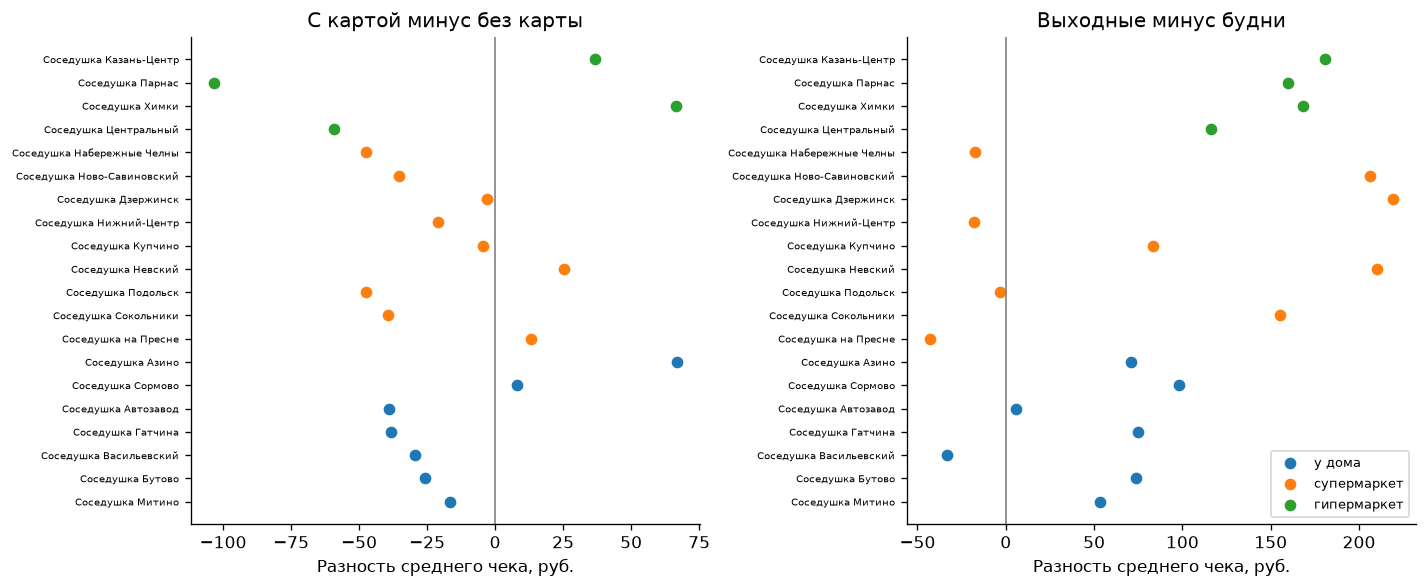

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, column, title in zip(axes, ['card_diff', 'weekend_diff'],
                           ['С картой минус без карты', 'Выходные минус будни']):
    for f in order:
        part = store25[store25['format'] == f]
        ax.scatter(part[column], part['name'], label=f)
    ax.axvline(0, color='gray', linewidth=1)
    ax.set(title=title, xlabel='Разность среднего чека, руб.')
    ax.tick_params(axis='y', labelsize=6)
axes[1].legend(fontsize=8)
fig.tight_layout()
fig.savefig(ROOT / 'figures/03_differences.png')
plt.show()

## 7. Выводы и рекомендации
Ниже результаты подставляются из расчётов, чтобы текстовые числа не расходились с таблицами.

In [14]:
by_id = results.set_index('hypothesis')
total_growth = (annual.loc[2025, 'revenue'] / annual.loc[2024, 'revenue'] - 1) * 100
receipt_growth = (annual.loc[2025, 'checks'] / annual.loc[2024, 'checks'] - 1) * 100
check_growth = (annual.loc[2025, 'mean_check'] / annual.loc[2024, 'mean_check'] - 1) * 100
summary = [
    f"**Динамика сети.** Выручка в 2025 году — {annual.loc[2025, 'revenue']:,.2f} руб., рост {total_growth:.2f}%. Число чеков выросло на {receipt_growth:.2f}%, средний чек — на {check_growth:.2f}%. Рост выручки связан и с числом покупок, и с размером покупки; это бухгалтерское разложение, а не доказательство причин роста.",
    f"**Форматы (H1).** {by_id.loc['H1', 'decision']}, p Холма = {by_id.loc['H1', 'p_holm']:.6g}. Медианы магазинных средних чеков: " + '; '.join(f"{f}: {format_summary.loc[f, 'median_store_check']:.2f} руб." for f in order) + '. Сравнивать точки для управленческого рейтинга разумно в рамках одного формата. Общий тест не определяет, какие именно пары различаются.',
    f"**Распространённость роста (H2).** Положительная разность выручки у {(store25['revenue_diff']>0).sum()} из {len(store25)} магазинов. {by_id.loc['H2', 'decision']}, p Холма = {by_id.loc['H2', 'p_holm']:.6g}. Это показывает направления изменений по точкам, но не отделяет рост цен от роста физического спроса.",
    f"**Лояльность (H3).** Средняя по магазинам разность чеков с картой и без неё: {store25['card_diff'].mean():.2f} руб.; медиана разностей: {store25['card_diff'].median():.2f} руб. {by_id.loc['H3', 'decision']}, p Холма = {by_id.loc['H3', 'p_holm']:.6g}. По этому сравнению нельзя утверждать, что карта увеличивает или снижает траты: пользователи карты сами выбирают участие и могут отличаться от остальных покупателей.",
    f"**Использование карт (H4).** {by_id.loc['H4', 'decision']}, p Холма = {by_id.loc['H4', 'p_holm']:.6g}. Медианы долей чеков с картой: " + '; '.join(f"{f}: {100*format_summary.loc[f, 'median_card_share']:.2f}%" for f in order) + '. При малом числе магазинов отсутствие значимости не является доказательством одинаковой вовлечённости.',
    f"**Площадь (H5).** Корреляция Спирмена = {rho:.3f}. {by_id.loc['H5', 'decision']}, p Холма = {by_id.loc['H5', 'p_holm']:.6g}. На графике нужно смотреть также на формат: общая связь может отражать различия типов магазинов. Для решения о расширении помещения нужны затраты на аренду, маржа, трафик и анализ сопоставимых точек.",
    f"**Выходные (H6).** Средняя по магазинам разность среднего чека выходных и будней: {store25['weekend_diff'].mean():.2f} руб. {by_id.loc['H6', 'decision']}, p Холма = {by_id.loc['H6', 'p_holm']:.6g}. Планировать график персонала только по среднему чеку нельзя: для этого нужны число покупок и нагрузка по часам."
]
conclusions = '\n\n'.join(summary)
display(Markdown(conclusions))
(ROOT / 'results/conclusions.md').write_text(conclusions, encoding='utf-8')

**Динамика сети.** Выручка в 2025 году — 11,457,582.40 руб., рост 9.83%. Число чеков выросло на 6.82%, средний чек — на 2.81%. Рост выручки связан и с числом покупок, и с размером покупки; это бухгалтерское разложение, а не доказательство причин роста.

**Форматы (H1).** H0 отклонена, p Холма = 0.0005. Медианы магазинных средних чеков: у дома: 483.37 руб.; супермаркет: 981.41 руб.; гипермаркет: 1688.16 руб.. Сравнивать точки для управленческого рейтинга разумно в рамках одного формата. Общий тест не определяет, какие именно пары различаются.

**Распространённость роста (H2).** Положительная разность выручки у 20 из 20 магазинов. H0 отклонена, p Холма = 1.14441e-05. Это показывает направления изменений по точкам, но не отделяет рост цен от роста физического спроса.

**Лояльность (H3).** Средняя по магазинам разность чеков с картой и без неё: -14.70 руб.; медиана разностей: -23.27 руб. H0 не отклонена, p Холма = 0.230637. По этому сравнению нельзя утверждать, что карта увеличивает или снижает траты: пользователи карты сами выбирают участие и могут отличаться от остальных покупателей.

**Использование карт (H4).** H0 не отклонена, p Холма = 0.9216. Медианы долей чеков с картой: у дома: 53.95%; супермаркет: 54.96%; гипермаркет: 55.25%. При малом числе магазинов отсутствие значимости не является доказательством одинаковой вовлечённости.

**Площадь (H5).** Корреляция Спирмена = 0.829. H0 отклонена, p Холма = 0.0008. На графике нужно смотреть также на формат: общая связь может отражать различия типов магазинов. Для решения о расширении помещения нужны затраты на аренду, маржа, трафик и анализ сопоставимых точек.

**Выходные (H6).** Средняя по магазинам разность среднего чека выходных и будней: 88.03 руб. H0 не отклонена, p Холма = 0.124168. Планировать график персонала только по среднему чеку нельзя: для этого нужны число покупок и нагрузка по часам.

1875

### Два результата, которые важно не упростить
**Площадь и выручка.** Общая корреляция 0,829 выглядит сильной. Однако внутри форматов описательные коэффициенты равны 0,000 для гипермаркетов, −0,286 для супермаркетов и −0,143 для магазинов у дома. Таким образом, положительная связь всей сети в основном отражает различия между форматами: гипермаркеты одновременно больше и имеют более высокую выручку. Внутри форматов наблюдений мало и диапазон площадей узкий; эти коэффициенты не доказывают отрицательный эффект площади. Практический вывод — не использовать общую корреляцию как обоснование расширения торговой площади.

**Выходные.** В 15 из 20 магазинов средний чек выходных выше. Исходное p-value критерия знаков равно 0,0414, но после поправки Холма — 0,1242. Поэтому на уровне всей семьи проверок H0 не отклоняется. При этом средняя разность составляет +88,03 руб., её индивидуальный bootstrap-интервал — примерно от +51,62 до +124,72 руб. Противоречия нет: интервал относится к средней величине разности и не скорректирован на множественность, а критерий знаков проверяет соотношение направлений изменений. Результат заслуживает дальнейшего исследования; утверждать, что эффекта нет, неверно.

### Что можно сделать дальше
1. **Руководителю розницы:** вести рейтинги внутри форматов и сопоставлять рост выручки с числом чеков, средним чеком и площадью. Добавить посещаемость, цены и маржу, чтобы отличать увеличение спроса от изменения цен и ассортимента.
2. **Менеджеру лояльности:** не объявлять программу успешной или неуспешной по разнице двух средних. Подготовить рандомизированный тест конкретного предложения среди подходящих клиентов. Основная метрика — маржа или выручка на клиента за фиксированный период; отдельно контролировать стоимость скидок и повторные покупки.
3. **Управляющим магазинов:** проверить календарные профили количества покупок и почасовой нагрузки. Сравнение среднего чека выходных и будней не заменяет анализ загрузки.
4. **Аналитику:** собрать ещё периоды и независимые магазины, а также сведения об акциях и локальных событиях. Для реального исследования продумать модель с учётом повторных клиентов, магазинов и времени, а не увеличивать формально объём выборки товарными строками.

### Ограничения
- Учебные данные, 20 магазинов, два года. Нет вероятностной выборки из реальных магазинов.
- Наблюдательный анализ: формат, площадь, регион и состав покупателей могут быть связаны друг с другом.
- Нет себестоимости, маржи, трафика, цены сопоставимой корзины и истории участия в программе лояльности.
- Критерий знаков устойчив к асимметрии, но маломощен на 20 наблюдениях и не использует величину изменения. Для слабых эффектов нужны новые данные, а не трактовка «p > 0,05» как равенства.
- Перестановочные p-value приближённые и воспроизводимы при заданном seed; их разрешение ограничено числом перестановок. Bootstrap-интервалы приблизительные, не одновременные и зависят от предположения независимости магазинов.

### Источники методов
- [SciPy: permutation_test](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.permutation_test.html)
- [SciPy: kruskal](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.kruskal.html)
- [SciPy: binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html)
- [SciPy: spearmanr](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.spearmanr.html)
- [statsmodels: multipletests, метод Holm](https://www.statsmodels.org/stable/generated/statsmodels.stats.multitest.multipletests.html)

## 8. Воспроизводимость
Все ячейки выполняются сверху вниз из папки проекта. В `data/` лежит исходный файл, в `results/` — таблицы и проверки качества, в `figures/` — графики. Итоговый HTML содержит код, результаты и графики и открывается без Python. Числа округляются только при отображении; проверки используют исходную точность.